In [1]:
import os
from datetime import datetime, timedelta

import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

## Реализация генератора

Ряд строится как сумма трёх компонент и шума:

`value(t) = base + trend(t) + seasonality(t) + noise(t)`

In [2]:
STEP_MINUTES = 5
PERIOD_1H = 12   # 1 час при шаге 5 минут
PERIOD_6H = 72   # 6 часов при шаге 5 минут

VARIANCE_MODES = ["const", "grow", "decay"]
TREND_MODES = ["none", "fast_up", "slow_up", "fast_down", "slow_down"]
SEASONALITY_MODES = ["none", "one", "two"]

# Суммарное изменение тренда за весь ряд
TREND_TOTAL = {"fast_up": 60.0, "slow_up": 15.0, "fast_down": -60.0, "slow_down": -15.0}


def _unique_path(path):
    if not os.path.exists(path):
        return path
    root, ext = os.path.splitext(path)
    i = 1
    while os.path.exists(f"{root}_{i}{ext}"):
        i += 1
    return f"{root}_{i}{ext}"


def generate_time_series(
    n_points=1000,
    variance="const",
    trend="none",
    seasonality="none",
    base=100.0,
    noise_std=2.0,
    seed=None,
    save_csv=True,
    csv_dir=".",
    save_plot=False,
    plot_path=None,
    show_plot=True,
):
    if n_points < 1:
        raise ValueError("n_points должно быть >= 1")

    rng = np.random.default_rng(seed)

    # Случайный выбор режимов
    if variance == "random":
        variance = str(rng.choice(VARIANCE_MODES))
    if trend == "random":
        trend = str(rng.choice(TREND_MODES))
    if seasonality == "random":
        seasonality = str(rng.choice(SEASONALITY_MODES))

    if variance not in VARIANCE_MODES:
        raise ValueError(f"Неизвестный режим дисперсии: {variance}")
    if trend not in TREND_MODES:
        raise ValueError(f"Неизвестный режим тренда: {trend}")
    if seasonality not in SEASONALITY_MODES:
        raise ValueError(f"Неизвестный режим сезонности: {seasonality}")

    # временная ось: с 00:00 текущего дня, шаг 5 минут
    start = datetime.now().replace(hour=0, minute=0, second=0, microsecond=0)
    timestamps = [start + timedelta(minutes=STEP_MINUTES * i) for i in range(n_points)]

    idx = np.arange(n_points)
    progress = idx / max(n_points - 1, 1)

    # тренд
    trend_values = np.zeros(n_points) if trend == "none" else TREND_TOTAL[trend] * progress

    # сезонность
    season_values = np.zeros(n_points)
    if seasonality in ("one", "two"):
        season_values += 10.0 * np.sin(2 * np.pi * idx / PERIOD_1H)
    if seasonality == "two":
        season_values += 20.0 * np.sin(2 * np.pi * idx / PERIOD_6H)

    # дисперсия:
    if variance == "const":
        sigma = np.full(n_points, noise_std)
    elif variance == "grow":
        sigma = noise_std * (0.25 + 3.75 * progress)
    else:
        sigma = noise_std * (4.0 - 3.75 * progress)

    noise = rng.normal(0.0, 1.0, n_points) * sigma

    values = base + trend_values + season_values + noise
    params = {"n_points": n_points, "variance": variance, "trend": trend,
              "seasonality": seasonality, "seed": seed}

    if save_csv:
        name = "ts_" + datetime.now().strftime("%Y%m%d_%H%M%S") + ".csv"
        path = _unique_path(os.path.join(csv_dir, name))
        with open(path, "w", encoding="utf-8") as f:
            f.write("timestamp,value\n")
            for t, v in zip(timestamps, values):
                f.write(f"{t:%Y-%m-%d %H:%M:%S},{v:.6f}\n")
        params["csv_file"] = path

    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(timestamps, values, lw=0.9)
    ax.set_title(f"variance={variance}, trend={trend}, seasonality={seasonality}, n={n_points}")
    ax.set_xlabel("Время")
    ax.set_ylabel("Значение")
    ax.grid(alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()

    if save_plot:
        if plot_path is None:
            raise ValueError("Укажите plot_path для сохранения графика")
        os.makedirs(os.path.dirname(plot_path) or ".", exist_ok=True)
        fig.savefig(plot_path, dpi=150)
        params["plot_file"] = plot_path

    if show_plot:
        plt.show()
    else:
        plt.close(fig)

    return timestamps, values, params

## Демонстрация случайной генерации

Все три параметра выбираются случайно (`random`).

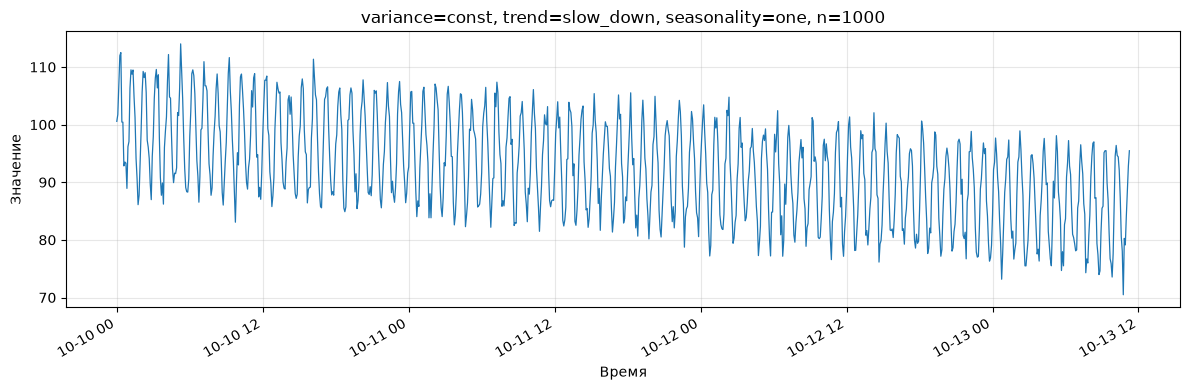

Параметры: {'n_points': 1000, 'variance': 'const', 'trend': 'slow_down', 'seasonality': 'one', 'seed': None, 'csv_file': '.\\ts_20261010_170656.csv'}
Первая точка: 2026-10-10 00:00:00 | Последняя точка: 2026-10-13 11:15:00
Шаг между точками: 0:05:00


In [3]:
ts, vals, p = generate_time_series(variance="random", trend="random", seasonality="random")
print("Параметры:", p)
print("Первая точка:", ts[0], "| Последняя точка:", ts[-1])
print("Шаг между точками:", ts[1] - ts[0])

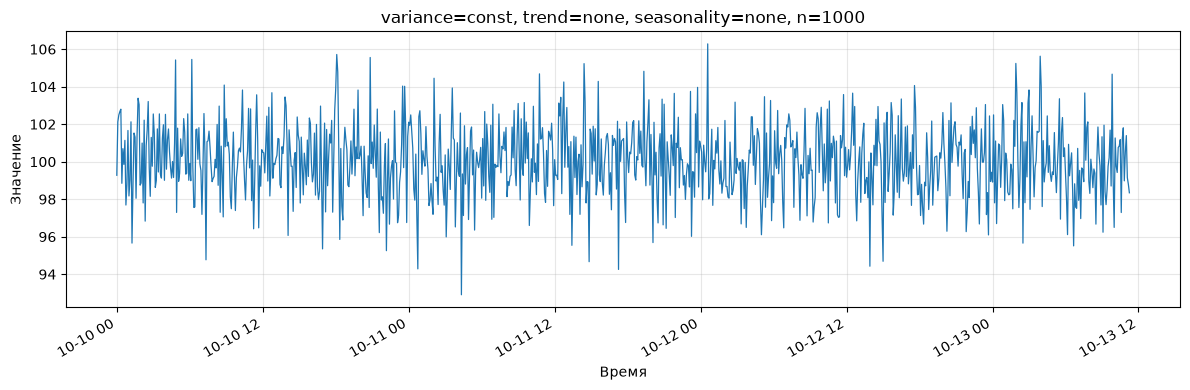

{'n_points': 1000, 'variance': 'const', 'trend': 'none', 'seasonality': 'none', 'seed': None, 'csv_file': '.\\ts_20261010_170656_1.csv'}


In [4]:
ts, vals, p = generate_time_series()
print(p)

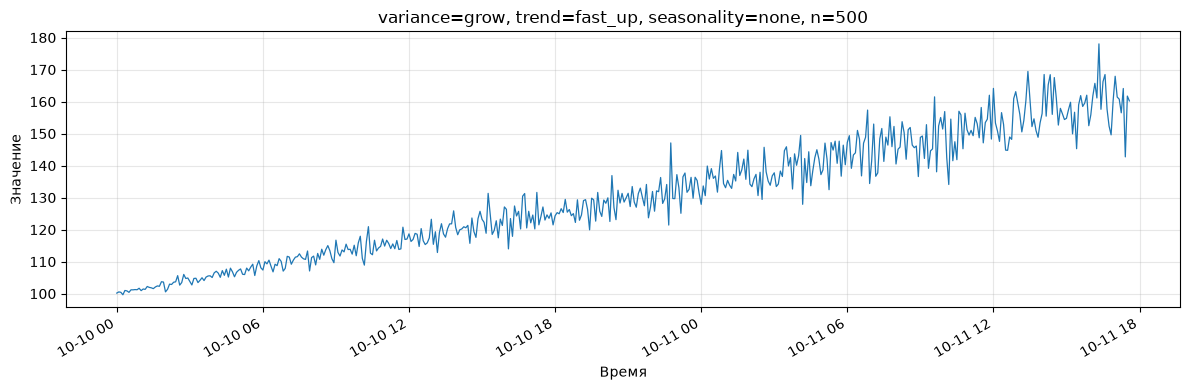

{'n_points': 500, 'variance': 'grow', 'trend': 'fast_up', 'seasonality': 'none', 'seed': 1, 'csv_file': '.\\ts_20261010_170656_2.csv'}


In [5]:
ts, vals, p = generate_time_series(n_points=500, variance='grow', trend='fast_up', seed=1)
print(p)

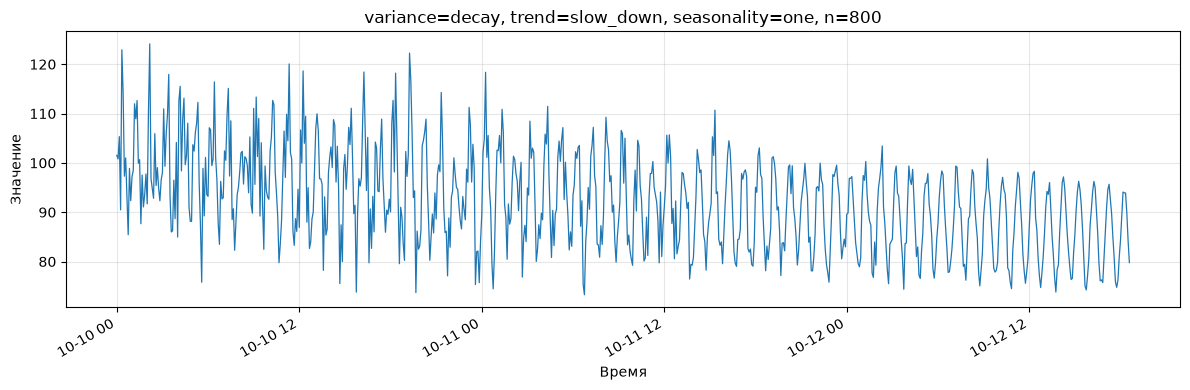

{'n_points': 800, 'variance': 'decay', 'trend': 'slow_down', 'seasonality': 'one', 'seed': 2, 'csv_file': '.\\ts_20261010_170656_3.csv'}


In [6]:
ts, vals, p = generate_time_series(n_points=800, variance='decay', trend='slow_down', seasonality='one', seed=2)
print(p)

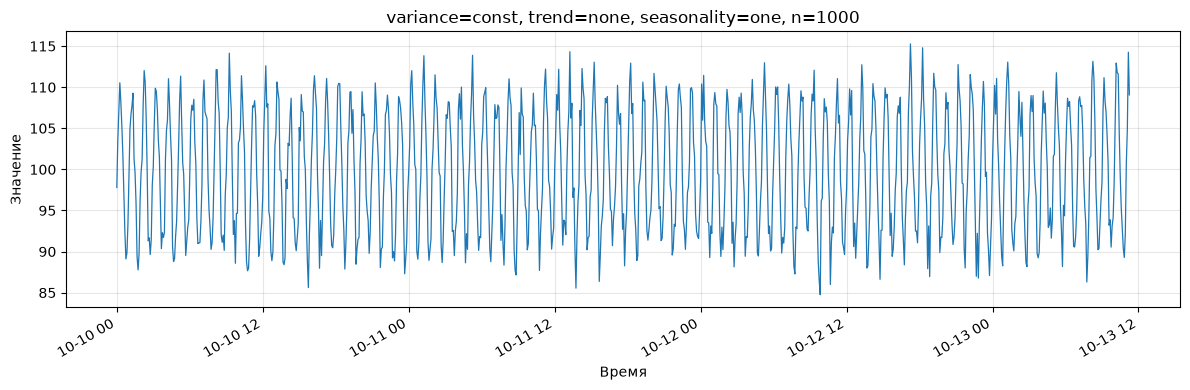

{'n_points': 1000, 'variance': 'const', 'trend': 'none', 'seasonality': 'one', 'seed': 10, 'csv_file': '.\\ts_20261010_170656_4.csv', 'plot_file': 'images/lab_image_1.png'}


In [7]:
_, _, p1 = generate_time_series(n_points=1000, variance="const", trend="none", seasonality="one",
                                seed=10, save_plot=True, plot_path="images/lab_image_1.png")
print(p1)

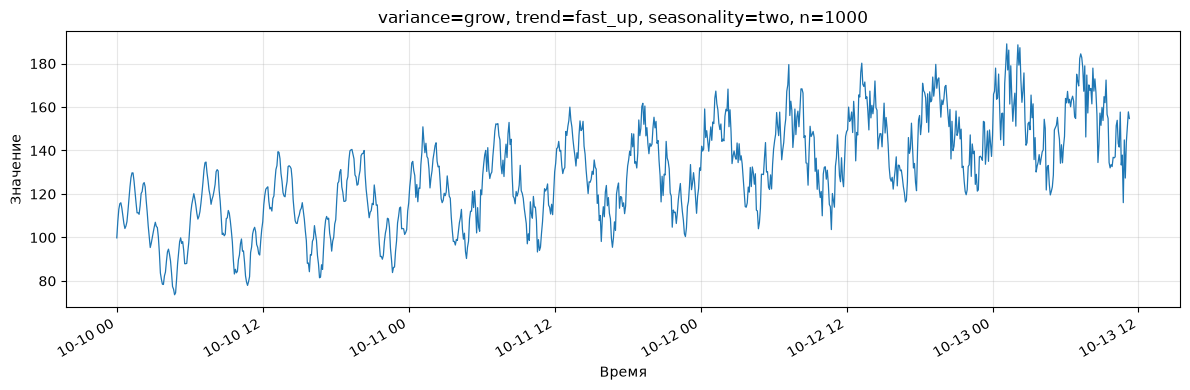

{'n_points': 1000, 'variance': 'grow', 'trend': 'fast_up', 'seasonality': 'two', 'seed': 20, 'csv_file': '.\\ts_20261010_170656_5.csv', 'plot_file': 'images/lab_image_2.png'}


In [8]:
_, _, p2 = generate_time_series(n_points=1000, variance="grow", trend="fast_up", seasonality="two",
                                seed=20, save_plot=True, plot_path="images/lab_image_2.png")
print(p2)

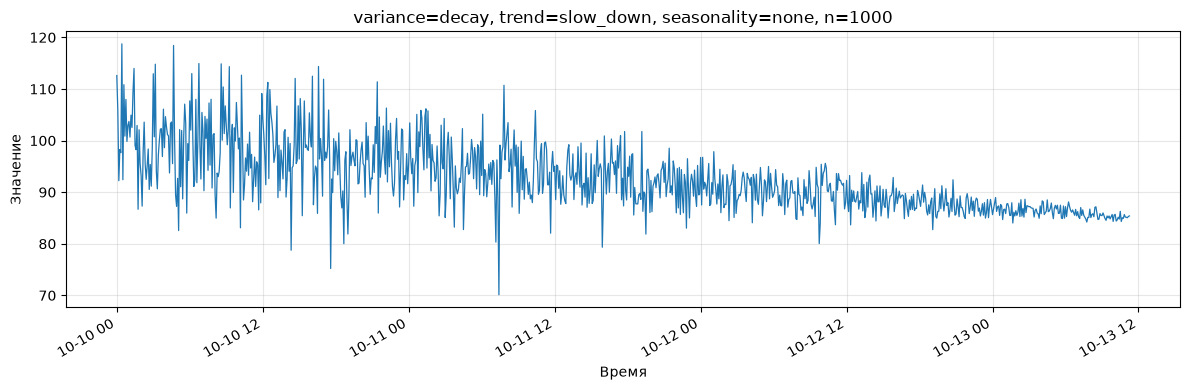

{'n_points': 1000, 'variance': 'decay', 'trend': 'slow_down', 'seasonality': 'none', 'seed': 30, 'csv_file': '.\\ts_20261010_170657.csv', 'plot_file': 'images/lab_image_3.png'}


In [9]:
_, _, p3 = generate_time_series(n_points=1000, variance="decay", trend="slow_down", seasonality="none",
                                seed=30, save_plot=True, plot_path="images/lab_image_3.png")
print(p3)